Import

Data Loading and Feature Extraction Reused from Homework 3

In [2]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

data_path = Path("../data/AReM")

In [3]:
activities = [
    "bending1",
    "bending2",
    "cycling",
    "lying",
    "sitting",
    "standing",
    "walking"
]

train_files = []
test_files = []

for activity in activities:
    activity_path = data_path / activity

    for file_path in activity_path.glob("dataset*.csv"):
        match = re.search(r"dataset(\d+)", file_path.stem)
        dataset_number = int(match.group(1))

        if activity in ["bending1", "bending2"]:
            is_test = dataset_number in [1, 2]
        else:
            is_test = dataset_number in [1, 2, 3]

        file_information = {
            "activity": activity,
            "dataset": dataset_number,
            "path": file_path
        }

        if is_test:
            test_files.append(file_information)
        else:
            train_files.append(file_information)

train_files = sorted(
    train_files,
    key=lambda item: (item["activity"], item["dataset"])
)

test_files = sorted(
    test_files,
    key=lambda item: (item["activity"], item["dataset"])
)

print("Training instances:", len(train_files))
print("Test instances:", len(test_files))
print("Total instances:", len(train_files) + len(test_files))

Training instances: 69
Test instances: 19
Total instances: 88


In [4]:
column_names = [
    "time",
    "avg_rss12",
    "var_rss12",
    "avg_rss13",
    "var_rss13",
    "avg_rss23",
    "var_rss23"
]

time_series_columns = column_names[1:]


def read_instance(file_path):
    with open(file_path, "r", encoding="utf-8") as file:
        first_data_line = next(
            line for line in file
            if line.strip() and not line.startswith("#")
        )

    if "," in first_data_line:
        separator = ","
    else:
        separator = r"\s+"

    data = pd.read_csv(
        file_path,
        comment="#",
        header=None,
        names=column_names,
        usecols=range(7),
        sep=separator,
        engine="python"
    )

    data = data.apply(
        pd.to_numeric,
        errors="coerce"
    ).dropna()

    return data.reset_index(drop=True)

In [5]:
def extract_time_domain_features(data, l=1):
    features = {}

    index_groups = np.array_split(
        np.arange(len(data)),
        l
    )

    for part_number, indices in enumerate(
        index_groups,
        start=1
    ):
        segment = data.iloc[indices]

        for series_number, column in enumerate(
            time_series_columns,
            start=1
        ):
            series = segment[column]
            suffix = f"ts{series_number}_part{part_number}"

            features[f"min_{suffix}"] = series.min()
            features[f"max_{suffix}"] = series.max()
            features[f"mean_{suffix}"] = series.mean()
            features[f"median_{suffix}"] = series.median()
            features[f"std_{suffix}"] = series.std()
            features[f"first_quart_{suffix}"] = series.quantile(0.25)
            features[f"third_quart_{suffix}"] = series.quantile(0.75)

    return features

In [6]:
def build_feature_dataset(file_list, l=1):
    rows = []

    for file_information in file_list:
        data = read_instance(file_information["path"])

        activity = file_information["activity"]

        row = {
            "activity": activity,
            "dataset": file_information["dataset"],
            "binary_label": (
                1 if activity in ["bending1", "bending2"] else 0
            )
        }

        row.update(
            extract_time_domain_features(data, l=l)
        )

        rows.append(row)

    return pd.DataFrame(rows)

In [7]:
train_features_l1 = build_feature_dataset(
    train_files,
    l=1
)

test_features_l1 = build_feature_dataset(
    test_files,
    l=1
)

print("Training feature data shape:", train_features_l1.shape)
print("Test feature data shape:", test_features_l1.shape)

display(train_features_l1.head())

Training feature data shape: (69, 45)
Test feature data shape: (19, 45)


,activity,dataset,binary_label,min_ts1_part1,max_ts1_part1,mean_ts1_part1,median_ts1_part1,std_ts1_part1,first_quart_ts1_part1,third_quart_ts1_part1,...,std_ts5_part1,first_quart_ts5_part1,third_quart_ts5_part1,min_ts6_part1,max_ts6_part1,mean_ts6_part1,median_ts6_part1,std_ts6_part1,first_quart_ts6_part1,third_quart_ts6_part1
0,bending1,3,1,35.00,47.40,43.954500,44.33,1.558835,43.00,45.00,...,1.999604,35.3625,36.50,0.0,1.79,0.493292,0.43,0.513506,0.00,0.94
1,bending1,4,1,33.00,47.75,42.179812,43.50,3.670666,39.15,45.00,...,3.849448,30.4575,36.33,0.0,2.18,0.613521,0.50,0.524317,0.00,1.00
2,bending1,5,1,33.00,45.75,41.678063,41.75,2.243490,41.33,42.75,...,2.411026,28.4575,31.25,0.0,1.79,0.383292,0.43,0.389164,0.00,0.50
3,bending1,6,1,37.00,48.00,43.454958,43.25,1.386098,42.50,45.00,...,2.488862,22.2500,24.00,0.0,5.26,0.679646,0.50,0.622534,0.43,0.87
4,bending1,7,1,36.25,48.00,43.969125,44.50,1.618364,43.31,44.67,...,3.318301,20.5000,23.75,0.0,2.96,0.555312,0.49,0.487826,0.00,0.83


In [8]:
print("Training binary labels:")
display(
    train_features_l1["binary_label"].value_counts()
)

print("Training activity labels:")
display(
    train_features_l1["activity"].value_counts()
)

Training binary labels:


binary_label
0    60
1     9
Name: count, dtype: int64

Training activity labels:


activity
cycling     12
lying       12
sitting     12
standing    12
walking     12
bending1     5
bending2     4
Name: count, dtype: int64

2 ) a

2 ) a i

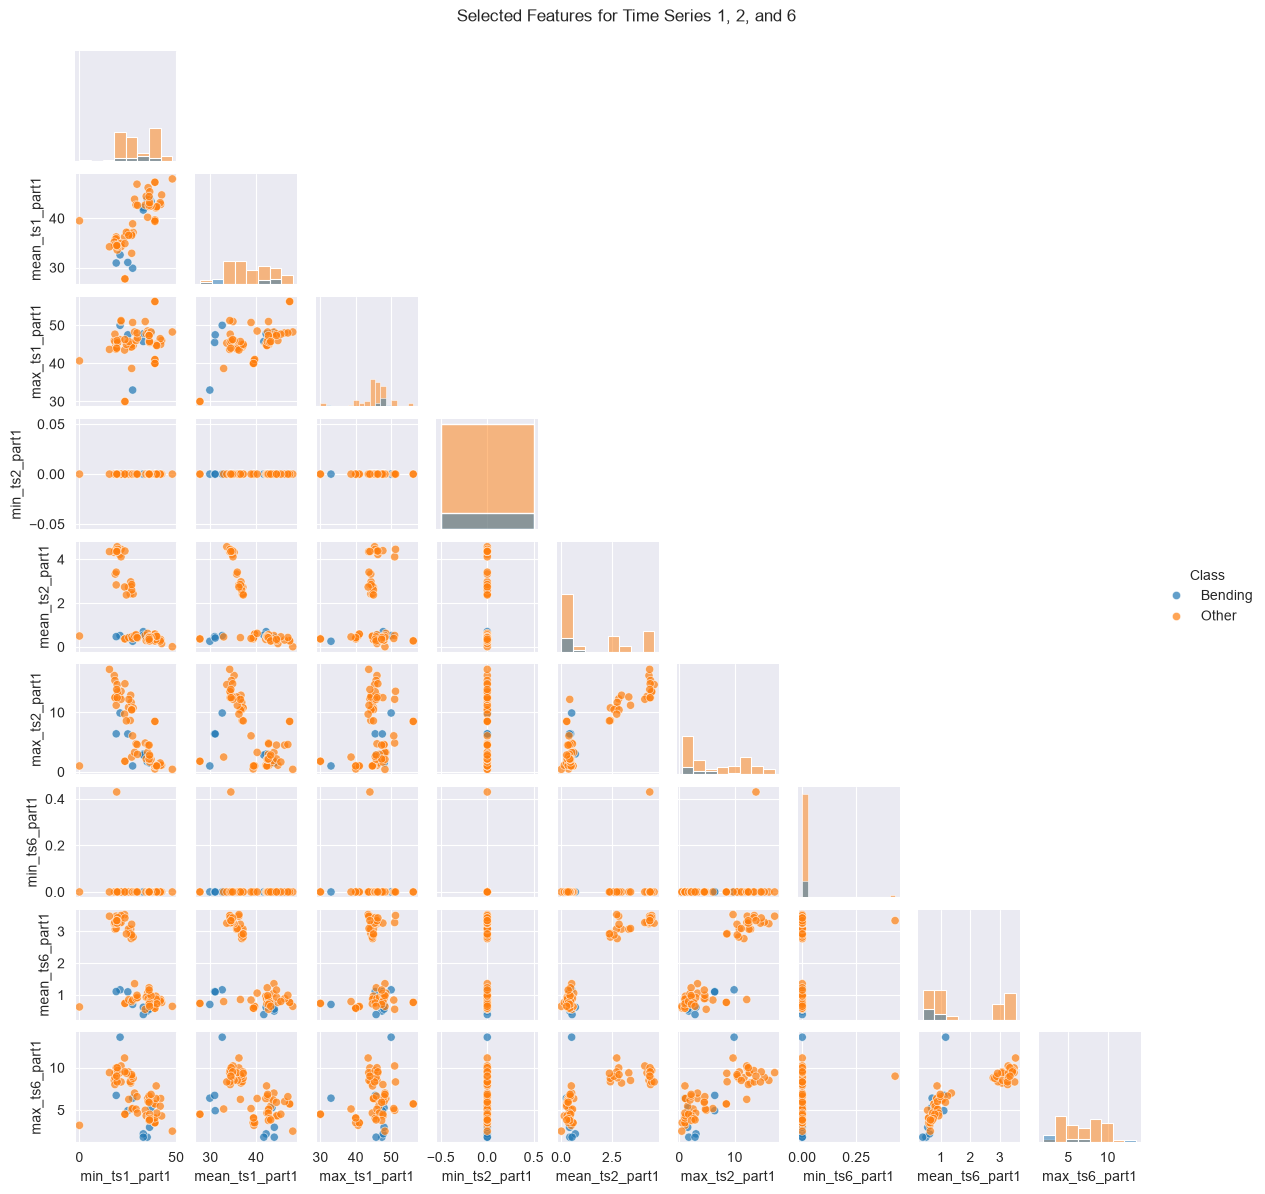

In [9]:
selected_series = [1, 2, 6]
selected_statistics = ["min", "mean", "max"]

plot_columns_l1 = [
    f"{statistic}_ts{series}_part1"
    for series in selected_series
    for statistic in selected_statistics
]

plot_data_l1 = train_features_l1[
    plot_columns_l1 + ["binary_label"]
].copy()

plot_data_l1["Class"] = plot_data_l1["binary_label"].map({
    0: "Other",
    1: "Bending"
})

plot_data_l1 = plot_data_l1.drop(
    columns="binary_label"
)

plot = sns.pairplot(
    plot_data_l1,
    vars=plot_columns_l1,
    hue="Class",
    corner=True,
    diag_kind="hist",
    height=1.3,
    plot_kws={"alpha": 0.7, "s": 35}
)

plot.fig.suptitle(
    "Selected Features for Time Series 1, 2, and 6",
    y=1.02
)

plt.show()

2 ) a i Answer

The two classes are partially separable. The mean and maximum features from time series 2 and 6 provide the clearest distinction, while the minimum features provide little information because most values are near zero. Some overlap remains, so no single pair of features perfectly separates bending from other activities.



2 ) a ii

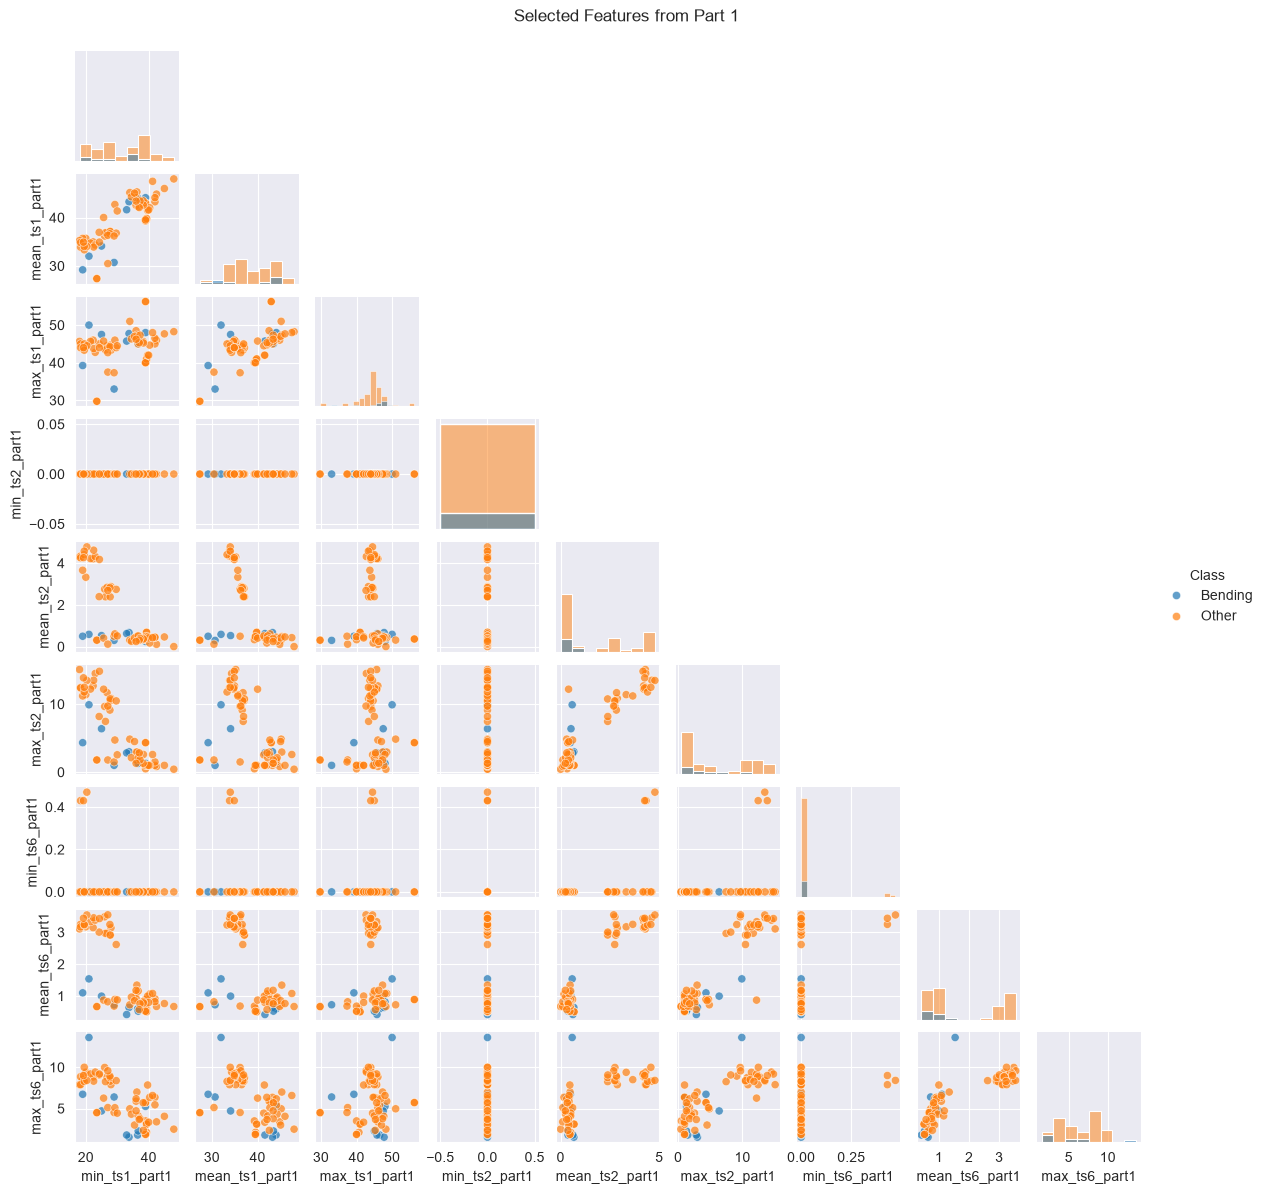

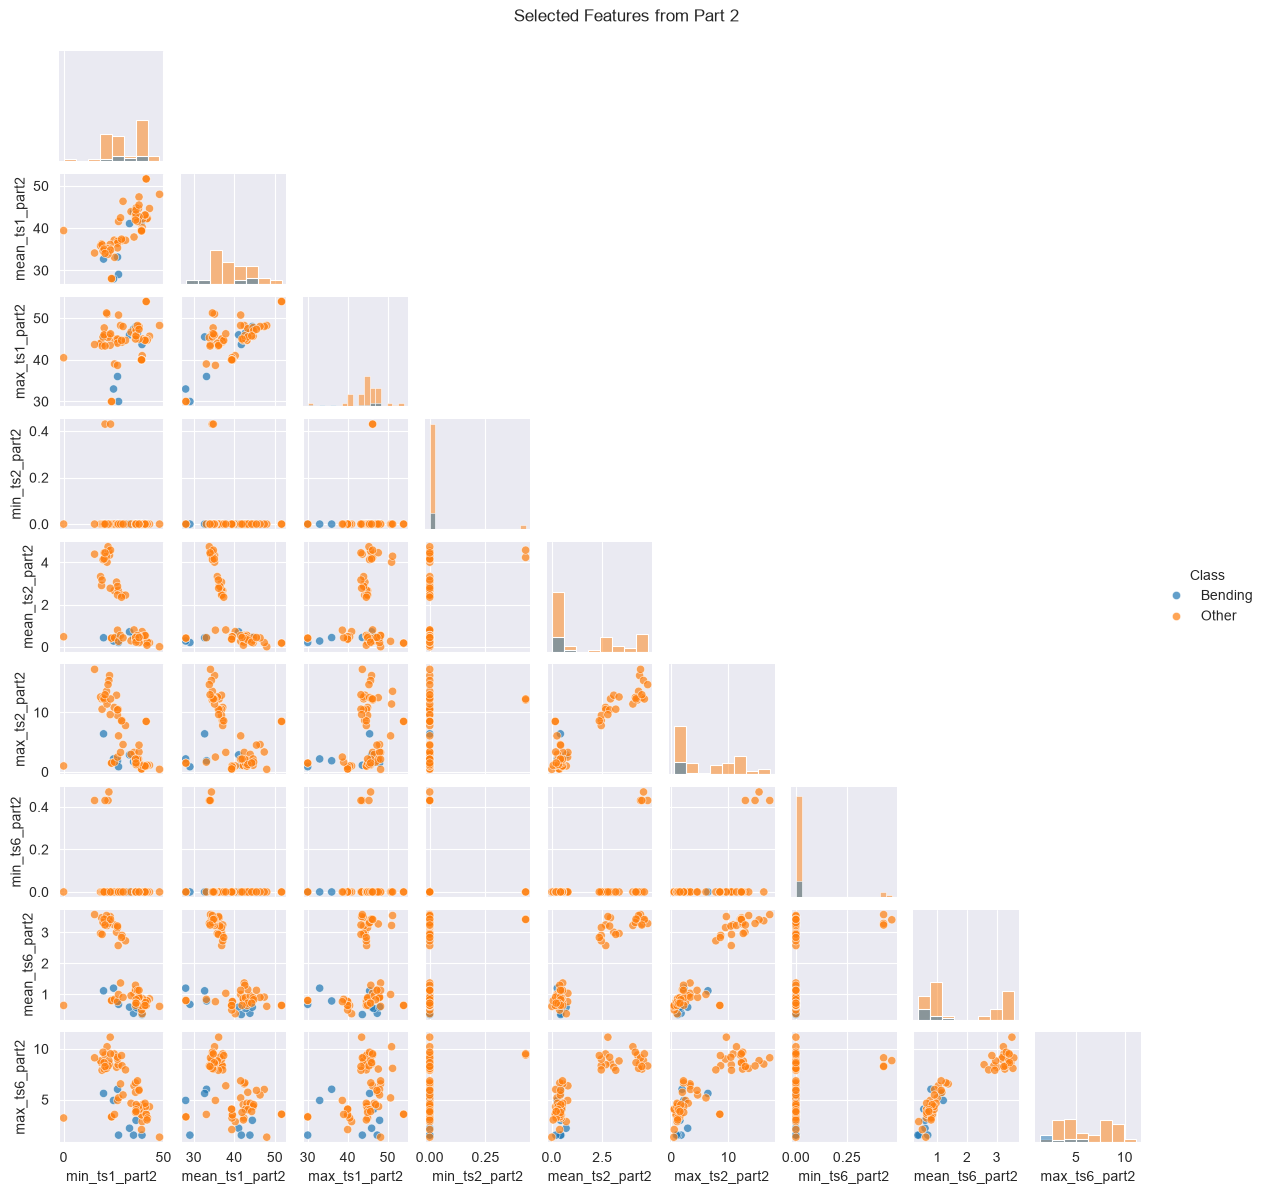

In [10]:
train_features_l2 = build_feature_dataset(
    train_files,
    l=2
)

for part in [1, 2]:
    plot_columns_l2 = [
        f"{statistic}_ts{series}_part{part}"
        for series in selected_series
        for statistic in selected_statistics
    ]

    plot_data_l2 = train_features_l2[
        plot_columns_l2 + ["binary_label"]
    ].copy()

    plot_data_l2["Class"] = plot_data_l2[
        "binary_label"
    ].map({
        0: "Other",
        1: "Bending"
    })

    plot_data_l2 = plot_data_l2.drop(
        columns="binary_label"
    )

    plot = sns.pairplot(
        plot_data_l2,
        vars=plot_columns_l2,
        hue="Class",
        corner=True,
        diag_kind="hist",
        height=1.3,
        plot_kws={"alpha": 0.7, "s": 35}
    )

    plot.fig.suptitle(
        f"Selected Features from Part {part}",
        y=1.02
    )

    plt.show()

2 ) a ii Answer

After dividing each time series into two parts, the classes remain only partially separable. The additional features provide slightly more information, but there is still considerable overlap compared with 2(a)i.

2 ) a iii

In [11]:
from sklearn.feature_selection import RFECV
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

metadata_columns = [
    "activity",
    "dataset",
    "binary_label"
]

cross_validation = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rfecv_models = {}
feature_names_by_l = {}
cv_results = []

for l in range(1, 21):
    current_data = build_feature_dataset(
        train_files,
        l=l
    )

    X_current = current_data.drop(
        columns=metadata_columns
    )

    y_current = current_data["binary_label"]

    logistic_pipeline = Pipeline([
        ("scaler", StandardScaler()),
        (
            "logistic",
            LogisticRegression(
                C=1e6,
                solver="liblinear",
                max_iter=5000,
                random_state=42
            )
        )
    ])

    selector = RFECV(
        estimator=logistic_pipeline,
        step=1,
        cv=cross_validation,
        scoring="accuracy",
        min_features_to_select=1,
        importance_getter="named_steps.logistic.coef_",
        n_jobs=-1
    )

    selector.fit(X_current, y_current)

    best_score_for_l = selector.cv_results_[
        "mean_test_score"
    ].max()

    rfecv_models[l] = selector
    feature_names_by_l[l] = X_current.columns

    cv_results.append({
        "l": l,
        "p": selector.n_features_,
        "CV Accuracy": best_score_for_l
    })

cv_results_df = pd.DataFrame(cv_results)

display(cv_results_df)

,l,p,CV Accuracy
0,1,13,0.971429
1,2,3,0.957143
2,3,6,0.928571
3,4,16,0.957143
4,5,6,0.957143
5,6,5,0.971429
6,7,6,0.941758
7,8,56,0.942857
8,9,348,0.957143
9,10,16,0.971429


In [12]:
best_result = cv_results_df.sort_values(
    by=["CV Accuracy", "p", "l"],
    ascending=[False, True, True]
).iloc[0]

best_l = int(best_result["l"])
best_p = int(best_result["p"])
best_cv_accuracy = best_result["CV Accuracy"]

best_selector = rfecv_models[best_l]
best_feature_names = feature_names_by_l[best_l]

selected_features = best_feature_names[
    best_selector.support_
].tolist()

print("Best l:", best_l)
print("Best p:", best_p)
print("Best CV accuracy:", best_cv_accuracy)
print("Selected features:")

for feature in selected_features:
    print(feature)

Best l: 20
Best p: 6
Best CV accuracy: 1.0
Selected features:
mean_ts5_part3
median_ts5_part3
first_quart_ts5_part3
third_quart_ts1_part12
median_ts4_part15
std_ts5_part19


2 ) a iii Answer

The best combination is l = 20 and p = 6, with a 5-fold cross-validation accuracy of 1.0. Stratified cross-validation was used because the classes are imbalanced.
The correct method performs feature selection separately within each training fold. Selecting features using the entire dataset before cross-validation would cause data leakage and produce overly optimistic accuracy.

2 ) a iv

In [13]:
from scipy.stats import norm
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)

best_train_data = build_feature_dataset(
    train_files,
    l=best_l
)

X_train_best = best_train_data[
    selected_features
]

y_train_best = best_train_data[
    "binary_label"
]

final_scaler = StandardScaler()

X_train_scaled = final_scaler.fit_transform(
    X_train_best
)

final_logistic_model = LogisticRegression(
    C=1e6,
    solver="liblinear",
    max_iter=5000,
    random_state=42
)

final_logistic_model.fit(
    X_train_scaled,
    y_train_best
)

train_probabilities = final_logistic_model.predict_proba(
    X_train_scaled
)[:, 1]

train_predictions = (
    train_probabilities >= 0.5
).astype(int)

train_accuracy = accuracy_score(
    y_train_best,
    train_predictions
)

train_auc = roc_auc_score(
    y_train_best,
    train_probabilities
)

# Calculate approximate Wald p-values
design_matrix = np.column_stack([
    np.ones(len(X_train_scaled)),
    X_train_scaled
])

coefficients = np.concatenate([
    final_logistic_model.intercept_,
    final_logistic_model.coef_.ravel()
])

weights = train_probabilities * (
    1 - train_probabilities
)

weights = np.clip(
    weights,
    1e-10,
    None
)

information_matrix = (
    design_matrix.T
    @ (design_matrix * weights[:, None])
)

covariance_matrix = np.linalg.pinv(
    information_matrix
)

standard_errors = np.sqrt(
    np.maximum(
        np.diag(covariance_matrix),
        0
    )
)

z_scores = np.divide(
    coefficients,
    standard_errors,
    out=np.full_like(coefficients, np.nan),
    where=standard_errors > 0
)

p_values = 2 * norm.sf(
    np.abs(z_scores)
)

parameter_table = pd.DataFrame({
    "Term": ["Intercept"] + selected_features,
    "Coefficient": coefficients,
    "p-value": p_values
})

print("Training accuracy:", train_accuracy)
print("Training AUC:", train_auc)

display(parameter_table)

Training accuracy: 1.0
Training AUC: 1.0


,Term,Coefficient,p-value
0,Intercept,-15.758963,0.954962
1,mean_ts5_part3,6.005255,0.998845
2,median_ts5_part3,4.014415,0.998427
3,first_quart_ts5_part3,6.080476,0.997959
4,third_quart_ts1_part12,-5.029456,0.969760
5,median_ts4_part15,-1.993435,0.995933
6,std_ts5_part19,-4.765009,0.962423


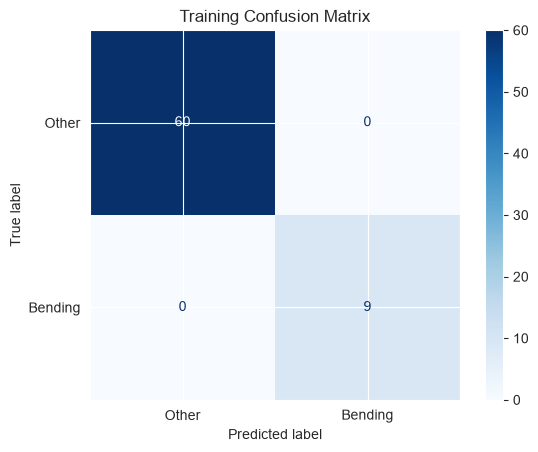

In [14]:
training_confusion_matrix = confusion_matrix(
    y_train_best,
    train_predictions,
    labels=[0, 1]
)

ConfusionMatrixDisplay(
    confusion_matrix=training_confusion_matrix,
    display_labels=["Other", "Bending"]
).plot(cmap="Blues")

plt.title("Training Confusion Matrix")
plt.show()

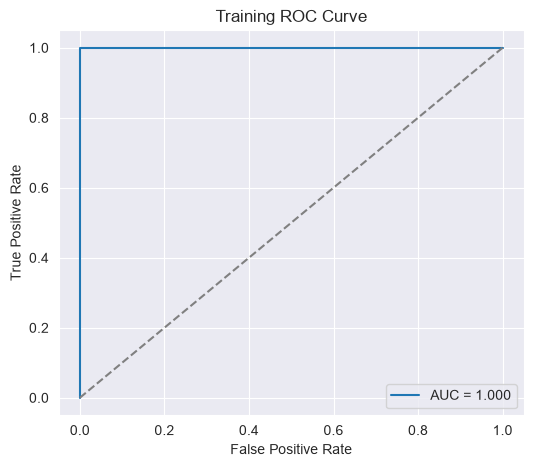

In [15]:
false_positive_rate, true_positive_rate, _ = roc_curve(
    y_train_best,
    train_probabilities
)

plt.figure(figsize=(6, 5))

plt.plot(
    false_positive_rate,
    true_positive_rate,
    label=f"AUC = {train_auc:.3f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Training ROC Curve")
plt.legend()
plt.show()

2 ) a iv Answer

The training accuracy and AUC are both 1.0. The confusion matrix shows that all 60 Other instances and all 9 Bending instances were classified correctly.
However, all reported coefficient p-values are greater than 0.05. These p-values are unreliable because the perfect separation of the classes makes the logistic regression coefficient estimates unstable.

2 ) a v

In [16]:
best_test_data = build_feature_dataset(
    test_files,
    l=best_l
)

X_test_best = best_test_data[
    selected_features
]

y_test_best = best_test_data[
    "binary_label"
]

X_test_scaled = final_scaler.transform(
    X_test_best
)

test_probabilities = final_logistic_model.predict_proba(
    X_test_scaled
)[:, 1]

test_predictions = (
    test_probabilities >= 0.5
).astype(int)

test_accuracy = accuracy_score(
    y_test_best,
    test_predictions
)

print("Cross-validation accuracy:", best_cv_accuracy)
print("Test accuracy:", test_accuracy)

Cross-validation accuracy: 1.0
Test accuracy: 0.9473684210526315


2 ) a v Answer

The cross-validation accuracy is 1.0, while the test accuracy is approximately 0.9474. The test accuracy is slightly lower, but the classifier still generalizes well.

2 ) a vi

In [17]:
training_errors = (
    train_predictions != y_train_best.to_numpy()
).sum()

largest_coefficient = np.abs(
    final_logistic_model.coef_
).max()

print("Number of training errors:", training_errors)
print(
    "Largest absolute coefficient:",
    largest_coefficient
)

Number of training errors: 0
Largest absolute coefficient: 6.080475798137553


2 ) a vi Answer

Yes. The model has zero training errors, indicating that the classes are perfectly separated on the training set. This separation may cause unstable coefficient estimates and unreliable p-values.

2 ) a vii

In [27]:
from scipy.special import expit

positive_indices = np.flatnonzero(
    y_train_best.to_numpy() == 1
)

negative_indices = np.flatnonzero(
    y_train_best.to_numpy() == 0
)

random_generator = np.random.default_rng(42)

sampled_negative_indices = random_generator.choice(
    negative_indices,
    size=len(positive_indices),
    replace=False
)

balanced_indices = np.concatenate([
    positive_indices,
    sampled_negative_indices
])

random_generator.shuffle(
    balanced_indices
)

X_balanced = X_train_best.iloc[
    balanced_indices
]

y_balanced = y_train_best.iloc[
    balanced_indices
]

print("Original class counts:")
display(y_train_best.value_counts())

print("Case-control sample counts:")
display(y_balanced.value_counts())

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression


scaler_cc = StandardScaler()

X_balanced_scaled = scaler_cc.fit_transform(
    X_balanced
)

case_control_model = LogisticRegression(
    C=1e6,
    max_iter=5000,
    random_state=42
)

case_control_model.fit(
    X_balanced_scaled,
    y_balanced
)


original_rate = y_train_best.mean()
sample_rate = y_balanced.mean()

intercept_adjustment = (
    np.log(original_rate / (1 - original_rate))
    - np.log(sample_rate / (1 - sample_rate))
)

adjusted_intercept = (
    case_control_model.intercept_[0]
    + intercept_adjustment
)

print("Adjusted intercept:", adjusted_intercept)

Original class counts:


binary_label
0    60
1     9
Name: count, dtype: int64

Case-control sample counts:


binary_label
0    9
1    9
Name: count, dtype: int64

Adjusted intercept: -0.17717260227368214


Case-control training accuracy: 1.0
Case-control training AUC: 1.0


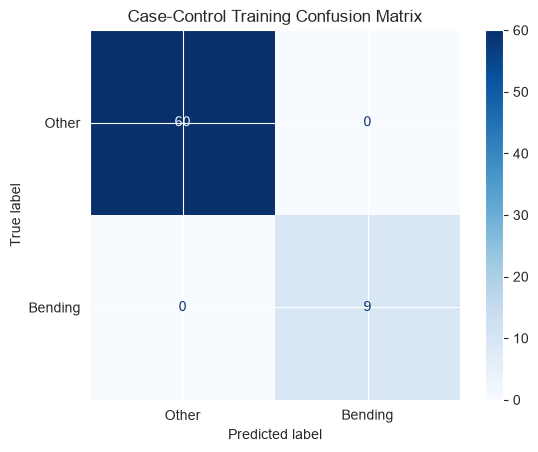

In [28]:
X_full_case_control_scaled = (
    scaler_cc.transform(X_train_best)
)

adjusted_logits = (
    X_full_case_control_scaled
    @ case_control_model.coef_.ravel()
    + adjusted_intercept
)

adjusted_probabilities = expit(
    adjusted_logits
)

adjusted_predictions = (
    adjusted_probabilities >= 0.5
).astype(int)

case_control_confusion_matrix = confusion_matrix(
    y_train_best,
    adjusted_predictions,
    labels=[0, 1]
)

case_control_auc = roc_auc_score(
    y_train_best,
    adjusted_probabilities
)

case_control_accuracy = accuracy_score(
    y_train_best,
    adjusted_predictions
)

print(
    "Case-control training accuracy:",
    case_control_accuracy
)

print(
    "Case-control training AUC:",
    case_control_auc
)

ConfusionMatrixDisplay(
    confusion_matrix=case_control_confusion_matrix,
    display_labels=["Other", "Bending"]
).plot(cmap="Blues")

plt.title(
    "Case-Control Training Confusion Matrix"
)

plt.show()

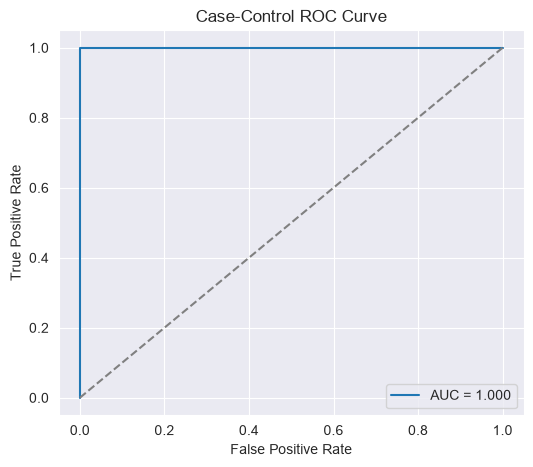

In [29]:
case_false_positive_rate, case_true_positive_rate, _ = (
    roc_curve(
        y_train_best,
        adjusted_probabilities
    )
)

plt.figure(figsize=(6, 5))

plt.plot(
    case_false_positive_rate,
    case_true_positive_rate,
    label=f"AUC = {case_control_auc:.3f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Case-Control ROC Curve")
plt.legend()
plt.show()

2 ) a vii Answer

The original training set is imbalanced, with 60 Other instances and 9 Bending instances. Case-control sampling produced a balanced sample with 9 instances from each class.

2 ) b

2 ) b i

In [34]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score
import numpy as np
import pandas as pd

C_values = np.logspace(-4, 4, 20)

l1_results = []
best_l1_score = -1

for l in range(1, 21):
    current_data = build_feature_dataset(
        train_files,
        l=l
    )

    X_current = current_data.drop(
        columns=metadata_columns
    )

    y_current = current_data["binary_label"]

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("logistic", LogisticRegression(
            l1_ratio=1,
            solver="liblinear",
            max_iter=5000,
            random_state=42
        ))
    ])

    search = GridSearchCV(
        pipeline,
        {"logistic__C": C_values},
        cv=cross_validation,
        scoring="accuracy",
        n_jobs=-1
    )

    search.fit(X_current, y_current)

    l1_results.append({
        "l": l,
        "C": search.best_params_["logistic__C"],
        "CV Accuracy": search.best_score_
    })

    if search.best_score_ > best_l1_score:
        best_l1_score = search.best_score_
        best_l_l1 = l
        best_C_l1 = search.best_params_[
            "logistic__C"
        ]
        best_l1_model = search.best_estimator_
        X_train_l1 = X_current

l1_results_df = pd.DataFrame(l1_results)
display(l1_results_df)

coefficients = (
    best_l1_model
    .named_steps["logistic"]
    .coef_[0]
)

selected_l1_features = X_train_l1.columns[
    np.abs(coefficients) > 1e-8
].tolist()

best_test_data_l1 = build_feature_dataset(
    test_files,
    l=best_l_l1
)

X_test_l1 = best_test_data_l1[
    X_train_l1.columns
]

y_test_l1 = best_test_data_l1[
    "binary_label"
]

l1_test_predictions = best_l1_model.predict(
    X_test_l1
)

l1_test_accuracy = accuracy_score(
    y_test_l1,
    l1_test_predictions
)

print("Best l:", best_l_l1)
print("Best C:", best_C_l1)
print("Best CV accuracy:", best_l1_score)
print("Test accuracy:", l1_test_accuracy)
print(
    "Number of selected features:",
    len(selected_l1_features)
)

,l,C,CV Accuracy
0,1,10000.000000,0.971429
1,2,0.615848,0.957143
2,3,0.233572,0.971429
3,4,0.615848,0.957143
4,5,4.281332,0.941758
5,6,29.763514,0.957143
6,7,0.615848,0.927473
7,8,545.559478,0.942857
8,9,3792.690191,0.928571
9,10,78.475997,0.971429


Best l: 19
Best C: 0.615848211066026
Best CV accuracy: 0.9857142857142858
Test accuracy: 0.9473684210526315
Number of selected features: 6


2 ) b i Answer

The best L1 logistic regression model uses l = 19 and C = 0.6158. It selected 6 features and achieved a cross-validation accuracy of 0.9857 and a test accuracy of 0.9474.

2 ) b ii

In [35]:
comparison = pd.DataFrame({
    "Method": [
        "P-value/RFE Logistic Regression",
        "L1 Logistic Regression"
    ],
    "CV Accuracy": [
        cv_results_df["CV Accuracy"].max(),
        best_l1_score
    ],
    "Test Accuracy": [
        test_accuracy,
        l1_test_accuracy
    ]
})

display(comparison)

,Method,CV Accuracy,Test Accuracy
0,P-value/RFE Logistic Regression,1.000000,0.947368
1,L1 Logistic Regression,0.985714,0.947368


2 ) b ii Answer

The p-value/RFE method had a slightly higher cross-validation accuracy, but both methods achieved the same test accuracy of 0.9474. Therefore, their test performance is equivalent. L1 logistic regression is easier to implement because it performs feature selection automatically through regularization.

2 ) c 

2 ) c i

In [37]:
from sklearn.preprocessing import (
    StandardScaler,
    MinMaxScaler,
    LabelEncoder,
    label_binarize
)
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV,
    cross_val_score
)
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)
from sklearn.base import clone
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

first_train_data = build_feature_dataset(
    train_files,
    l=1
)

activity_encoder = LabelEncoder()

activity_encoder.fit(
    first_train_data["activity"]
)

minimum_class_count = (
    first_train_data["activity"]
    .value_counts()
    .min()
)

multiclass_cv = StratifiedKFold(
    n_splits=min(5, int(minimum_class_count)),
    shuffle=True,
    random_state=42
)

C_values = np.logspace(-4, 4, 20)

multiclass_lr_results = []
best_multiclass_lr_score = -1

for l in range(1, 21):
    current_data = build_feature_dataset(
        train_files,
        l=l
    )

    X_current = current_data.drop(
        columns=metadata_columns
    )

    y_current = activity_encoder.transform(
        current_data["activity"]
    )

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("logistic", LogisticRegression(
            l1_ratio=1,
            solver="saga",
            max_iter=20000,
            random_state=42
        ))
    ])

    search = GridSearchCV(
        pipeline,
        {"logistic__C": C_values},
        cv=multiclass_cv,
        scoring="accuracy",
        n_jobs=-1
    )

    search.fit(X_current, y_current)

    multiclass_lr_results.append({
        "l": l,
        "C": search.best_params_["logistic__C"],
        "CV Accuracy": search.best_score_
    })

    if search.best_score_ > best_multiclass_lr_score:
        best_multiclass_lr_score = search.best_score_
        best_multiclass_lr_l = l
        best_multiclass_lr_C = (
            search.best_params_["logistic__C"]
        )
        best_multiclass_lr_model = (
            search.best_estimator_
        )
        multiclass_lr_features = X_current.columns

display(pd.DataFrame(multiclass_lr_results))

print("Best l:", best_multiclass_lr_l)
print("Best C:", best_multiclass_lr_C)
print(
    "Best CV accuracy:",
    best_multiclass_lr_score
)

,l,C,CV Accuracy
0,1,1.623777,0.870098
1,2,545.559478,0.927288
2,3,1438.449888,0.898693
3,4,206.913808,0.883987
4,5,1438.449888,0.913399
5,6,3792.690191,0.913399
6,7,545.559478,0.883987
7,8,206.913808,0.840686
8,9,4.281332,0.883987
9,10,545.559478,0.825980


Best l: 2
Best C: 545.5594781168514
Best CV accuracy: 0.9272875816993464


In [39]:
def evaluate_multiclass_model(
    model,
    l,
    feature_columns,
    model_name
):
    test_data = build_feature_dataset(
        test_files,
        l=l
    )

    X_test = test_data[feature_columns]

    y_test = activity_encoder.transform(
        test_data["activity"]
    )

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)

    test_accuracy = accuracy_score(
        y_test,
        predictions
    )

    test_error = 1 - test_accuracy

    labels = np.arange(
        len(activity_encoder.classes_)
    )

    matrix = confusion_matrix(
        y_test,
        predictions,
        labels=labels
    )

    ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=activity_encoder.classes_
    ).plot(
        cmap="Blues",
        xticks_rotation=45
    )

    plt.title(
        f"{model_name} Confusion Matrix"
    )
    plt.show()

    y_test_binary = label_binarize(
        y_test,
        classes=labels
    )

    macro_auc = roc_auc_score(
        y_test_binary,
        probabilities,
        average="macro",
        multi_class="ovr"
    )

    plt.figure(figsize=(8, 6))

    for class_index, class_name in enumerate(
        activity_encoder.classes_
    ):
        false_positive_rate, true_positive_rate, _ = (
            roc_curve(
                y_test_binary[:, class_index],
                probabilities[:, class_index]
            )
        )

        plt.plot(
            false_positive_rate,
            true_positive_rate,
            label=class_name
        )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        color="gray"
    )

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"{model_name} ROC Curves")
    plt.legend()
    plt.show()

    print("Test error:", test_error)
    print("Macro-average AUC:", macro_auc)

    return test_error, macro_auc

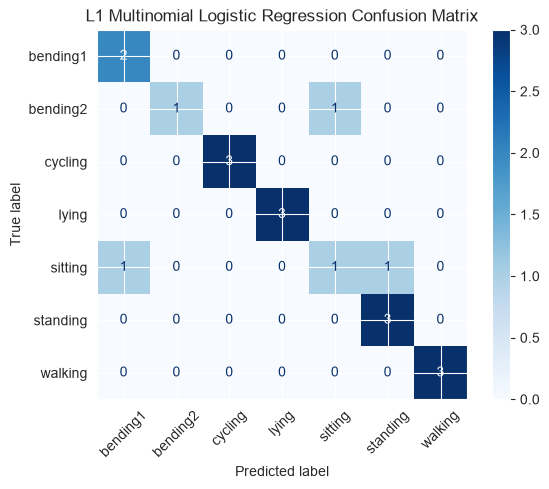

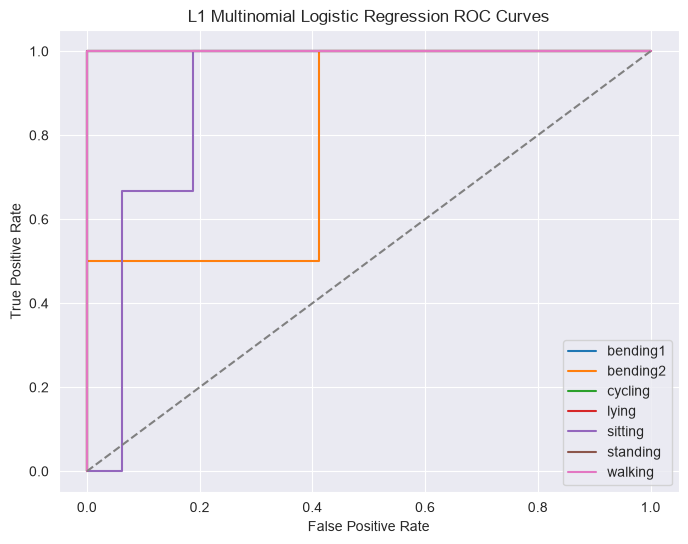

Test error: 0.1578947368421053
Macro-average AUC: 0.9557072829131652


In [40]:
multiclass_lr_test_error, multiclass_lr_auc = (
    evaluate_multiclass_model(
        best_multiclass_lr_model,
        best_multiclass_lr_l,
        multiclass_lr_features,
        "L1 Multinomial Logistic Regression"
    )
)

2 ) c i Answer

The L1-penalized multinomial logistic regression selected l = 2 and C = 545.56. Its test error was 0.1579, and its macro-average AUC was 0.9557, indicating good multiclass performance.

2 ) c ii

In [43]:
def select_naive_bayes_model(
    pipeline
):
    results = []
    best_score = -1

    for l in range(1, 21):
        current_data = build_feature_dataset(
            train_files,
            l=l
        )

        X_current = current_data.drop(
            columns=metadata_columns
        )

        y_current = activity_encoder.transform(
            current_data["activity"]
        )

        scores = cross_val_score(
            pipeline,
            X_current,
            y_current,
            cv=multiclass_cv,
            scoring="accuracy",
            n_jobs=-1
        )

        mean_score = scores.mean()

        results.append({
            "l": l,
            "CV Accuracy": mean_score
        })

        if mean_score > best_score:
            best_score = mean_score
            best_l = l
            best_features = X_current.columns

    best_data = build_feature_dataset(
        train_files,
        l=best_l
    )

    X_best = best_data[best_features]

    y_best = activity_encoder.transform(
        best_data["activity"]
    )

    best_model = clone(pipeline)
    best_model.fit(X_best, y_best)

    return (
        best_model,
        best_l,
        best_score,
        best_features,
        pd.DataFrame(results)
    )

In [44]:
from sklearn.naive_bayes import (
    GaussianNB,
    MultinomialNB
)

gaussian_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", GaussianNB())
])

multinomial_pipeline = Pipeline([
    ("scaler", MinMaxScaler(clip=True)),
    ("model", MultinomialNB())
])

(
    best_gaussian_model,
    best_gaussian_l,
    best_gaussian_cv,
    gaussian_features,
    gaussian_results
) = select_naive_bayes_model(
    gaussian_pipeline
)

(
    best_multinomial_nb_model,
    best_multinomial_nb_l,
    best_multinomial_nb_cv,
    multinomial_nb_features,
    multinomial_nb_results
) = select_naive_bayes_model(
    multinomial_pipeline
)

print("Gaussian NB best l:", best_gaussian_l)
print("Gaussian NB CV accuracy:", best_gaussian_cv)

print(
    "Multinomial NB best l:",
    best_multinomial_nb_l
)
print(
    "Multinomial NB CV accuracy:",
    best_multinomial_nb_cv
)

Gaussian NB best l: 1
Gaussian NB CV accuracy: 0.8415032679738563
Multinomial NB best l: 5
Multinomial NB CV accuracy: 0.7679738562091504


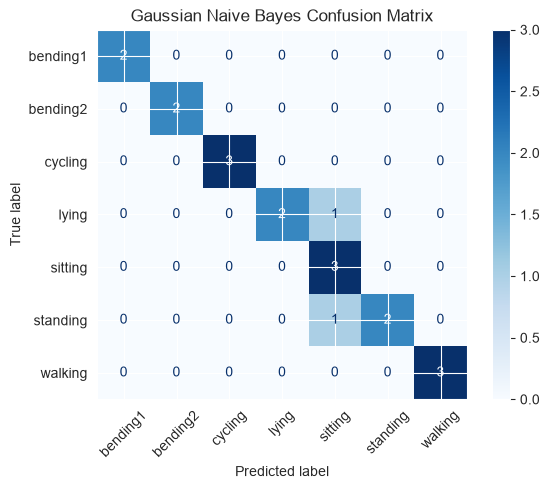

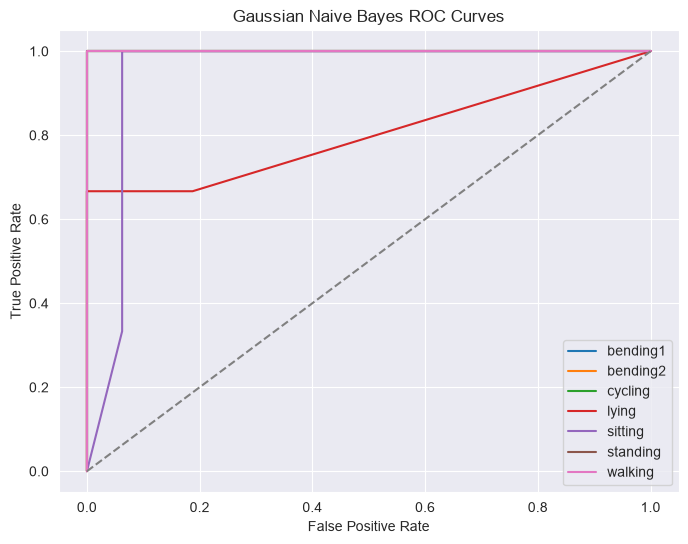

Test error: 0.10526315789473684
Macro-average AUC: 0.9642857142857143


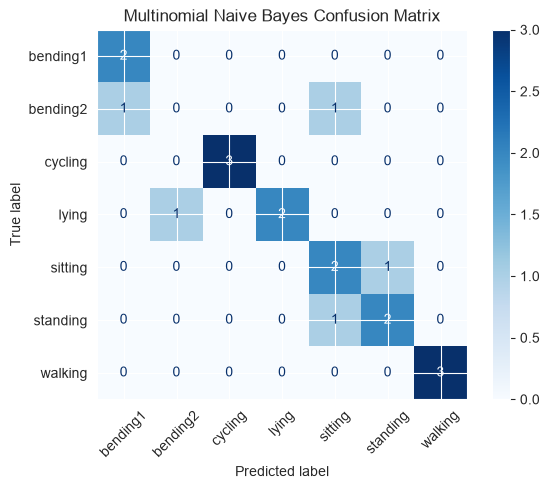

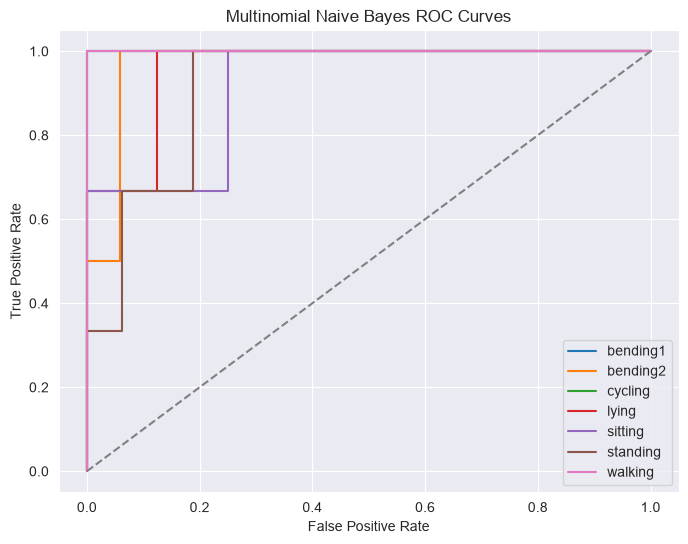

Test error: 0.26315789473684215
Macro-average AUC: 0.9660364145658263


In [45]:
gaussian_test_error, gaussian_auc = (
    evaluate_multiclass_model(
        best_gaussian_model,
        best_gaussian_l,
        gaussian_features,
        "Gaussian Naive Bayes"
    )
)

multinomial_nb_test_error, multinomial_nb_auc = (
    evaluate_multiclass_model(
        best_multinomial_nb_model,
        best_multinomial_nb_l,
        multinomial_nb_features,
        "Multinomial Naive Bayes"
    )
)

2 ) c ii Answer

Gaussian Naive Bayes selected l = 1 and achieved a test error of 0.1053 with a macro-average AUC of 0.9643. Multinomial Naive Bayes selected l = 5 and achieved a test error of 0.2632 with a macro-average AUC of 0.9660. Gaussian Naive Bayes produced fewer classification errors.

2 ) c iii

In [46]:
multiclass_comparison = pd.DataFrame({
    "Model": [
        "L1 Multinomial Logistic Regression",
        "Gaussian Naive Bayes",
        "Multinomial Naive Bayes"
    ],
    "Best l": [
        best_multiclass_lr_l,
        best_gaussian_l,
        best_multinomial_nb_l
    ],
    "CV Accuracy": [
        best_multiclass_lr_score,
        best_gaussian_cv,
        best_multinomial_nb_cv
    ],
    "Test Error": [
        multiclass_lr_test_error,
        gaussian_test_error,
        multinomial_nb_test_error
    ],
    "Macro AUC": [
        multiclass_lr_auc,
        gaussian_auc,
        multinomial_nb_auc
    ]
})

display(multiclass_comparison)

,Model,Best l,CV Accuracy,Test Error,Macro AUC
0,L1 Multinomial Logistic Regression,2,0.927288,0.157895,0.955707
1,Gaussian Naive Bayes,1,0.841503,0.105263,0.964286
2,Multinomial Naive Bayes,5,0.767974,0.263158,0.966036


2 ) c iii Answer

Gaussian Naive Bayes performed best because it had the lowest test error of 0.1053. L1 multinomial logistic regression ranked second, while Multinomial Naive Bayes had the highest test error.

3 ) ISLR 4.8.3

For class k, the Bayes classifier maximizes:
delta_k(x) = log(pi_k) - log(sigma_k) - (x - mu_k)^2 / (2 sigma_k^2)
Expanding the squared term gives:
delta_k(x) = -x^2 / (2 sigma_k^2) + mu_k x / sigma_k^2 - mu_k^2 / (2 sigma_k^2) - log(sigma_k) + log(pi_k)
Because the coefficient of x^2 depends on the class-specific variance, the decision boundary is quadratic rather than linear. If all classes had the same variance, the quadratic terms would cancel and the boundary would be linea

4 ) ISLR 4.8.7

P(Yes | X = 4) =
[0.8 × exp(-(4 - 10)^2 / 72)] /
[0.8 × exp(-(4 - 10)^2 / 72) + 0.2 × exp(-(4 - 0)^2 / 72)]
The resulting probability is approximately 0.7519.
Therefore, the company has approximately a 75.2% probability of issuing a dividend, so it should be classified as “Yes.”